# **Decision Trees and Cross Validation**

## Introduction



## Exploratory Data Analysis (EDA) and Imputation

Missing values in this data 

In [77]:
#Importing the relevant libraries 
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

#Importing the cross validation data split 
df_train = pd.read_csv("training_data.csv")
df_validate = pd.read_csv("validation_data.csv")
df_test = pd.read_csv("test_data.csv")

In [78]:
#Assessing if there are any null values and the size of the data set
df_train.isnull().sum()

AGE           4
SEX           0
INF_ANAM      3
STENOK_AN    65
FK_STENOK    43
             ..
GEPAR_S_n     7
ASP_S_n       7
TIKL_S_n      8
TRENT_S_n     8
mortality     0
Length: 108, dtype: int64

 Explanation need some sort of imputation. Website where code is from says no missing values for age so explore this. 

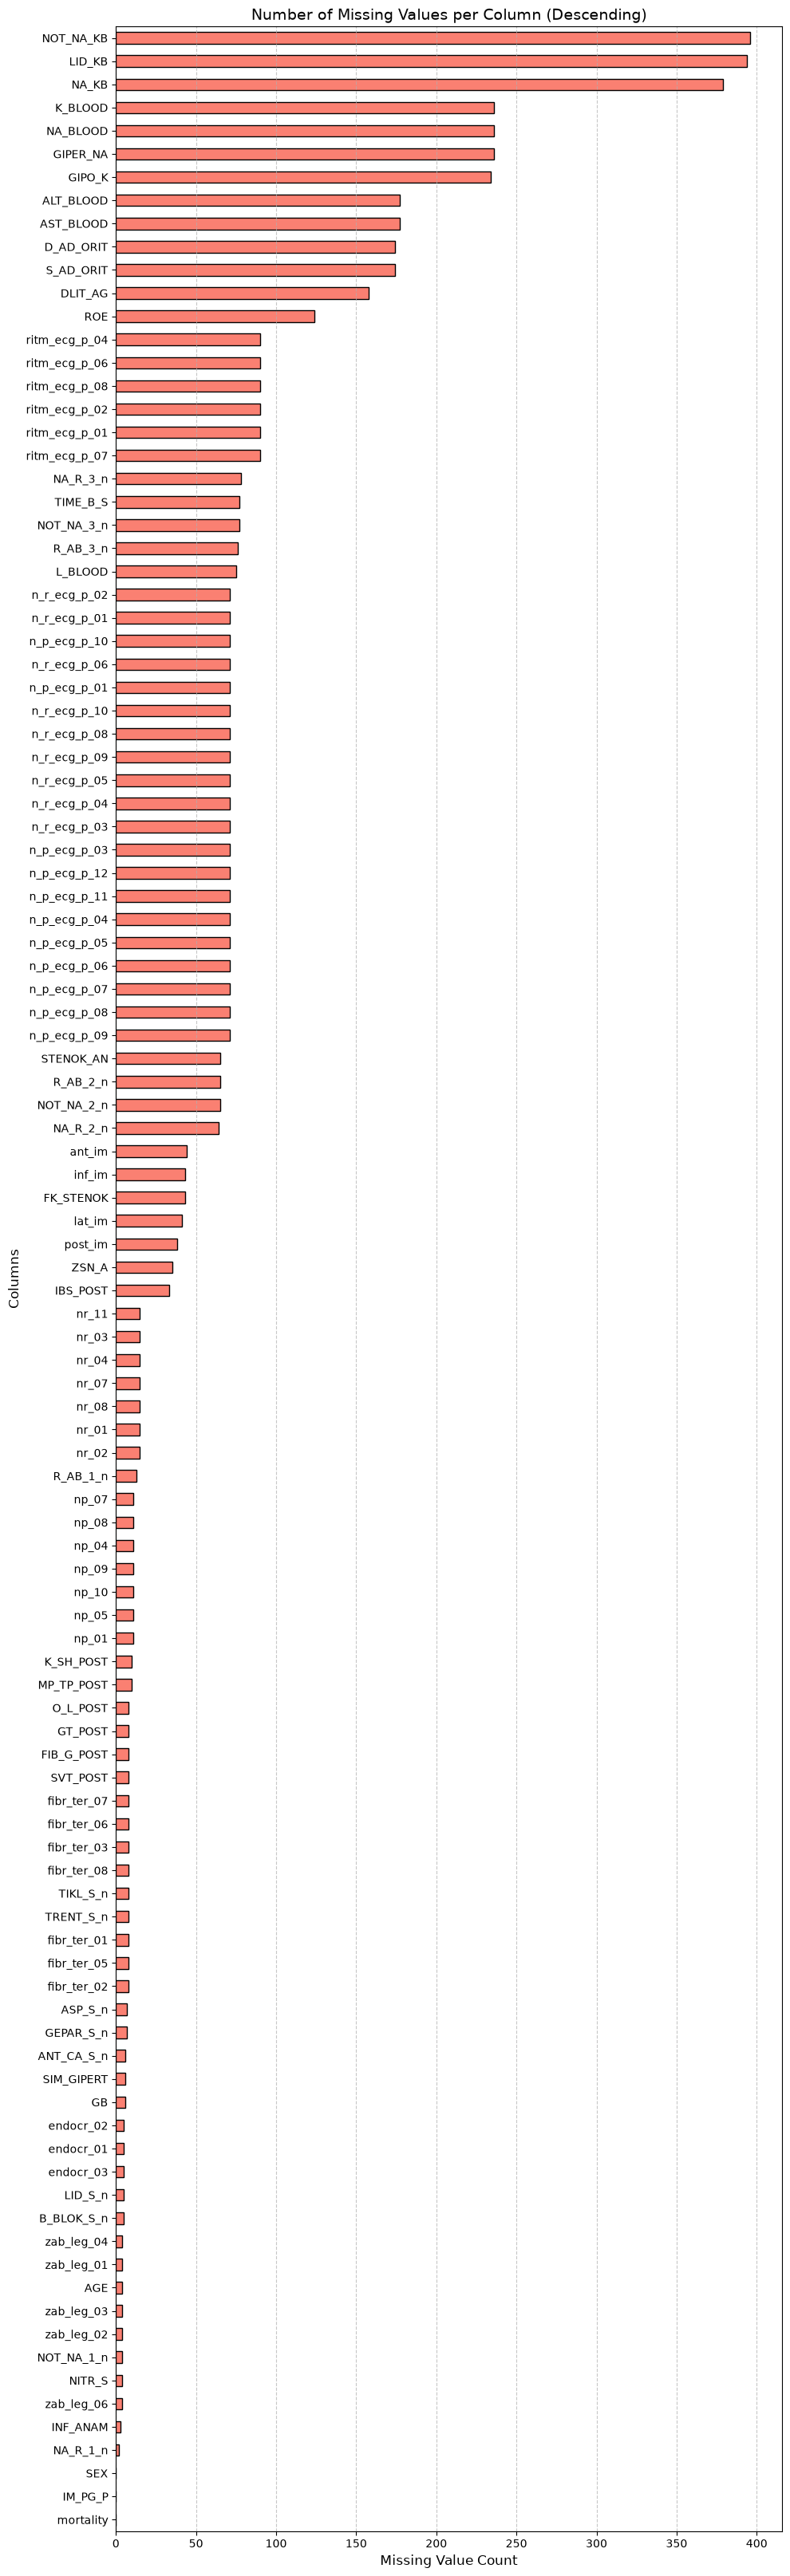

In [80]:
#PLOT OF MISSING VALUES

# 1. Calculate missing values and sort them in descending order
missing_values = df_train.isnull().sum().sort_values(ascending=False)

# Optional: Uncomment the line below if you only want to show columns that actually have missing values (> 0)
# missing_values = missing_values[missing_values > 0]

# 2. Create a horizontal bar plot and adjust figure height for readability
plt.figure(figsize=(10, max(6, len(missing_values) * 0.3))) # Dynamically scales height based on column count
missing_values.plot(kind='barh', color='salmon', edgecolor='black')

# 3. Customize the graph labels and layout
plt.title('Number of Missing Values per Column (Descending)', fontsize=14)
plt.xlabel('Missing Value Count', fontsize=12)
plt.ylabel('Columns', fontsize=12)
plt.gca().invert_yaxis()  # Puts the column with the highest missing values at the very top
plt.grid(axis='x', linestyle='--', alpha=0.7)

# 4. Display the plot
plt.tight_layout()
plt.show()

In [81]:
# Identify the top 3 columns with the most missing values
top_3_missing = df_train.isnull().sum().nlargest(3).index

print("Columns being dropped:")
print(top_3_missing)

# Drop these columns from both datasets
df_train = df_train.drop(columns=top_3_missing)
df_validate = df_validate.drop(columns=top_3_missing)

# Remove observations with missing AGE
df_train = df_train.dropna(subset=['AGE']).copy()
df_validate = df_validate.dropna(subset=['AGE']).copy()

# Check dimensions
print("Training:", df_train.shape)
print("Validation:", df_validate.shape)

Columns being dropped:
Index(['NOT_NA_KB', 'LID_KB', 'NA_KB'], dtype='str')
Training: (1016, 105)
Validation: (337, 105)


In [141]:
# Continuous numerical variables
numerical_cols = [
    'S_AD_ORIT',
    'D_AD_ORIT',
    'K_BLOOD',
    'NA_BLOOD',
    'ALT_BLOOD',
    'AST_BLOOD',
    'L_BLOOD',
    'ROE'
]

# Categorical variables
categorical_cols = [
    col for col in df_train.columns
    if col not in numerical_cols + ['AGE', 'mortality']
]

from sklearn.impute import SimpleImputer

# Initialise imputers
median_imputer = SimpleImputer(strategy='median')
mode_imputer = SimpleImputer(strategy='most_frequent')

# Median imputation for numerical variables
df_train[numerical_cols] = median_imputer.fit_transform(
    df_train[numerical_cols]
)

# Mode imputation for categorical variables
df_train[categorical_cols] = mode_imputer.fit_transform(
    df_train[categorical_cols]
)

In [83]:
# Median imputation for validation data
df_validate[numerical_cols] = median_imputer.transform(
    df_validate[numerical_cols]
)

# Mode imputation for validation data
df_validate[categorical_cols] = mode_imputer.transform(
    df_validate[categorical_cols]
)

In [84]:
# Check remaining missing values
print("Training missing values:")
print(df_train.isnull().sum().sum())

print("Validation missing values:")
print(df_validate.isnull().sum().sum())

# Check dataset dimensions
print("Training shape:", df_train.shape)
print("Validation shape:", df_validate.shape)

Training missing values:
0
Validation missing values:
0
Training shape: (1016, 105)
Validation shape: (337, 105)


In [85]:
print(df_train['mortality'].isnull().sum())
print(df_validate['mortality'].isnull().sum())

0
0


Talk about the imputation. Drop null values for age. Drop top 3 worst columns


In [142]:
#This is an unbalanced data set
print(df_train['mortality'].value_counts())

mortality
0    853
1    163
Name: count, dtype: int64


## Decision trees

A decision tree is a machine learning algorithm that can be used for classification. In this analysis....



To assess the quality of each model, 1-fold cross-validation is used  The model is trained using four folds and evaluated using the remaining fold. This process is repeated five times so that each fold is used as the validation set once.

The five accuracy values outputted in each section therefore represent the model's performance on five different subsets of the data. The mean accuracy provides an overall measure of predictive performance, while the standard deviation indicates how much the model's performance varies between folds.

The code used in this section is taken from the websites linked below. Variables have been altered to match this data set. 

In [161]:
# Load sklearn libraries
from sklearn.tree import DecisionTreeClassifier 
from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

In [175]:
# Training data
X_train = df_train.drop(columns=['mortality'])
y_train = df_train['mortality']

# Validation data
X_validate = df_validate.drop(columns=['mortality'])
y_validate = df_validate['mortality']

# Define maximum depths to investigate
depths = range(1, 16)

# List to store results
results = []

# Loop through different maximum depths
for depth in depths:

    # Loop through balanced and unbalanced models
    for weight in [None, 'balanced']:

        # Initialise decision tree
        dt = DecisionTreeClassifier(
            criterion='gini',
            max_depth=depth,
            class_weight=weight,
            random_state=42
        )

        # Train the decision tree
        dt.fit(X_train, y_train)

        # Calculate accuracy
        train_accuracy = dt.score(X_train, y_train)
        validate_accuracy = dt.score(X_validate, y_validate)

        # Store results
        results.append({
            'Max Depth': depth,
            'Class Weight': weight if weight else 'None',
            'Training Accuracy': train_accuracy,
            'Validation Accuracy': validate_accuracy
        })

# Create results DataFrame
depth_results = pd.DataFrame(results)
depth_results = depth_results.pivot(
    index='Max Depth',
    columns='Class Weight',
    values=['Training Accuracy', 'Validation Accuracy']
)


# Rename columns
depth_results.columns = [
    'Training (Unbalanced)',
    'Training (Balanced)',
    'Validation (Unbalanced)',
    'Validation (Balanced)'
]

# Round accuracy values to 4 decimal places
depth_results = depth_results.round(4)

# Display DataFrame
depth_results


,Training (Unbalanced),Training (Balanced),Validation (Unbalanced),Validation (Balanced)
Max Depth,,,,
1,0.8652,0.8583,0.8546,0.8487
2,0.8720,0.6220,0.8665,0.5875
3,0.8770,0.8474,0.8665,0.7834
4,0.8809,0.7579,0.8694,0.7033
5,0.8898,0.8012,0.8576,0.7033
6,0.9065,0.8356,0.8605,0.7270
7,0.9272,0.8809,0.8516,0.7567
8,0.9390,0.8967,0.8427,0.7329
9,0.9528,0.9203,0.8368,0.7715


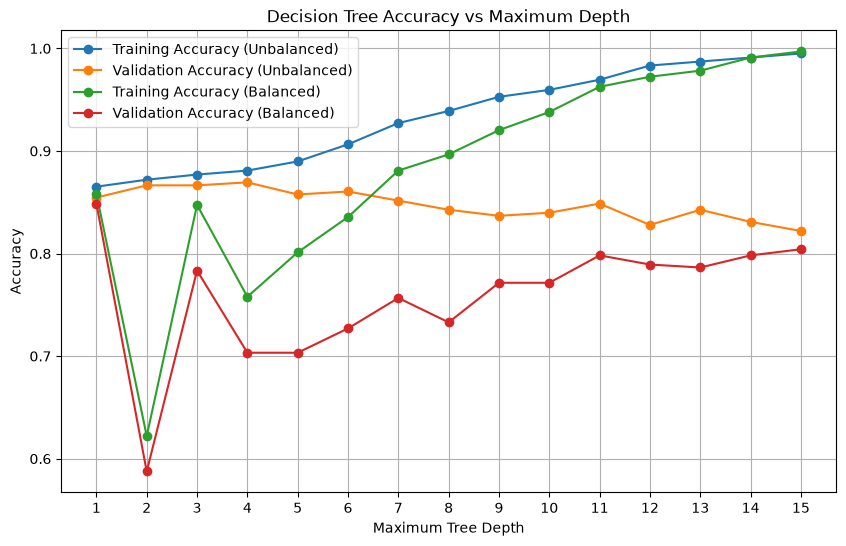

In [177]:
plt.figure(figsize=(10, 6))

# Training accuracy - Unbalanced
plt.plot(
    depths,
    depth_results['Training (Unbalanced)'],
    marker='o',
    label='Training Accuracy (Unbalanced)'
)

# Validation accuracy - Unbalanced
plt.plot(
    depths,
    depth_results['Validation (Unbalanced)'],
    marker='o',
    label='Validation Accuracy (Unbalanced)'
)

# Training accuracy - Balanced
plt.plot(
    depths,
    depth_results['Training (Balanced)'],
    marker='o',
    label='Training Accuracy (Balanced)'
)

# Validation accuracy - Balanced
plt.plot(
    depths,
    depth_results['Validation (Balanced)'],
    marker='o',
    label='Validation Accuracy (Balanced)'
)

plt.xlabel('Maximum Tree Depth')
plt.ylabel('Accuracy')
plt.title('Decision Tree Accuracy vs Maximum Depth')

plt.xticks(depths)
plt.legend()
plt.grid(True)

plt.show()

In [179]:
# Initialise final decision trees
dt_final_balanced = DecisionTreeClassifier(
    criterion='gini',
    max_depth=4,
    class_weight='balanced',
    random_state=42
)

dt_final_unbalanced = DecisionTreeClassifier(
    criterion='gini',
    max_depth=4,
    random_state=42
)

# Train final decision tree

dt_final_balanced.fit(X_train, y_train)
dt_final_unbalanced.fit(X_train, y_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",4
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at 

In [180]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Calculate performance metrics

# Create comparison DataFrame
comparison = pd.DataFrame([
    {
        'Model': name,
        'Training accuracy': model.score(X_train, y_train),
        'Validation accuracy': model.score(X_validate, y_validate),
        'Validation precision': precision_score(y_validate, model.predict(X_validate), zero_division=0),
        'Validation recall': recall_score(y_validate, model.predict(X_validate), zero_division=0),
        'Validation F1': f1_score(y_validate, model.predict(X_validate), zero_division=0)
    }
    for name, model in [
        ('Balanced', dt_final_balanced),
        ('Unbalanced', dt_final_unbalanced)
    ]
]).set_index('Model')

display(comparison)

,Training accuracy,Validation accuracy,Validation precision,Validation recall,Validation F1
Model,,,,,
Balanced,0.757874,0.703264,0.287037,0.574074,0.382716
Unbalanced,0.880906,0.869436,0.812500,0.240741,0.371429


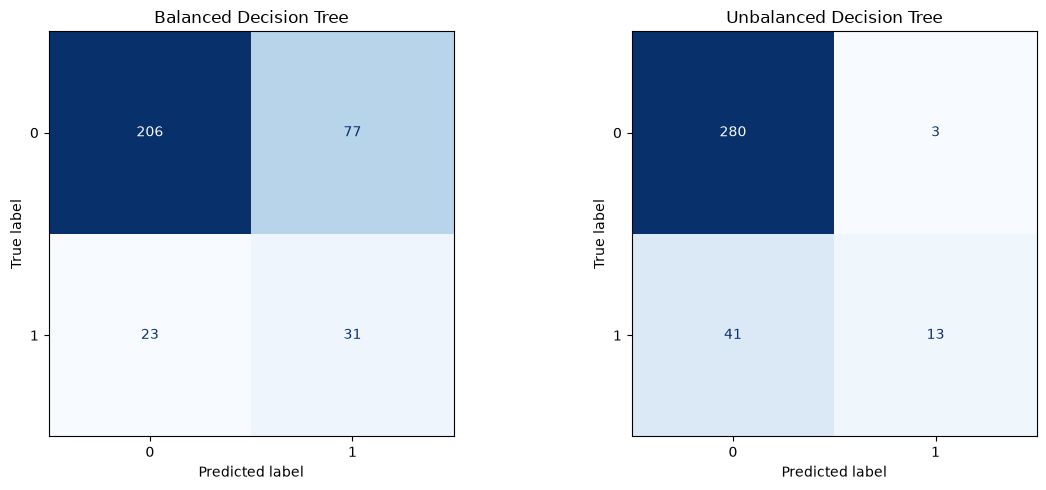

In [163]:
# Predictions using validation data
y_pred_balanced = dt_final_balanced.predict(X_validate)
y_pred_unbalanced = dt_final_unbalanced.predict(X_validate)

# Calculate confusion matrices
cm_balanced = confusion_matrix(y_validate, y_pred_balanced)
cm_unbalanced = confusion_matrix(y_validate, y_pred_unbalanced)

# Plot confusion matrices
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Balanced decision tree
ConfusionMatrixDisplay(
    confusion_matrix=cm_balanced
).plot(ax=axes[0], cmap='Blues', colorbar=False)

axes[0].set_title('Balanced Decision Tree')

# Unbalanced decision tree
ConfusionMatrixDisplay(
    confusion_matrix=cm_unbalanced
).plot(ax=axes[1], cmap='Blues', colorbar=False)

axes[1].set_title('Unbalanced Decision Tree')

plt.tight_layout()
plt.show()

The decision tree correctly classifies approximately ... Overfitting 

### Selecting the final model

Because mortality is the positive class, recall measures the proportion of patients who died that were correctly identified, while precision measures how many predicted deaths were actual deaths. F1-score balances these two measures. Here we select the model with the higher **validation F1-score**, breaking ties using recall. This rule is fixed before looking at test results. If your group prioritises missed deaths over false alarms, discuss whether recall or an F-beta score would be a more appropriate selection metric.
Going with ....  as final decision tree

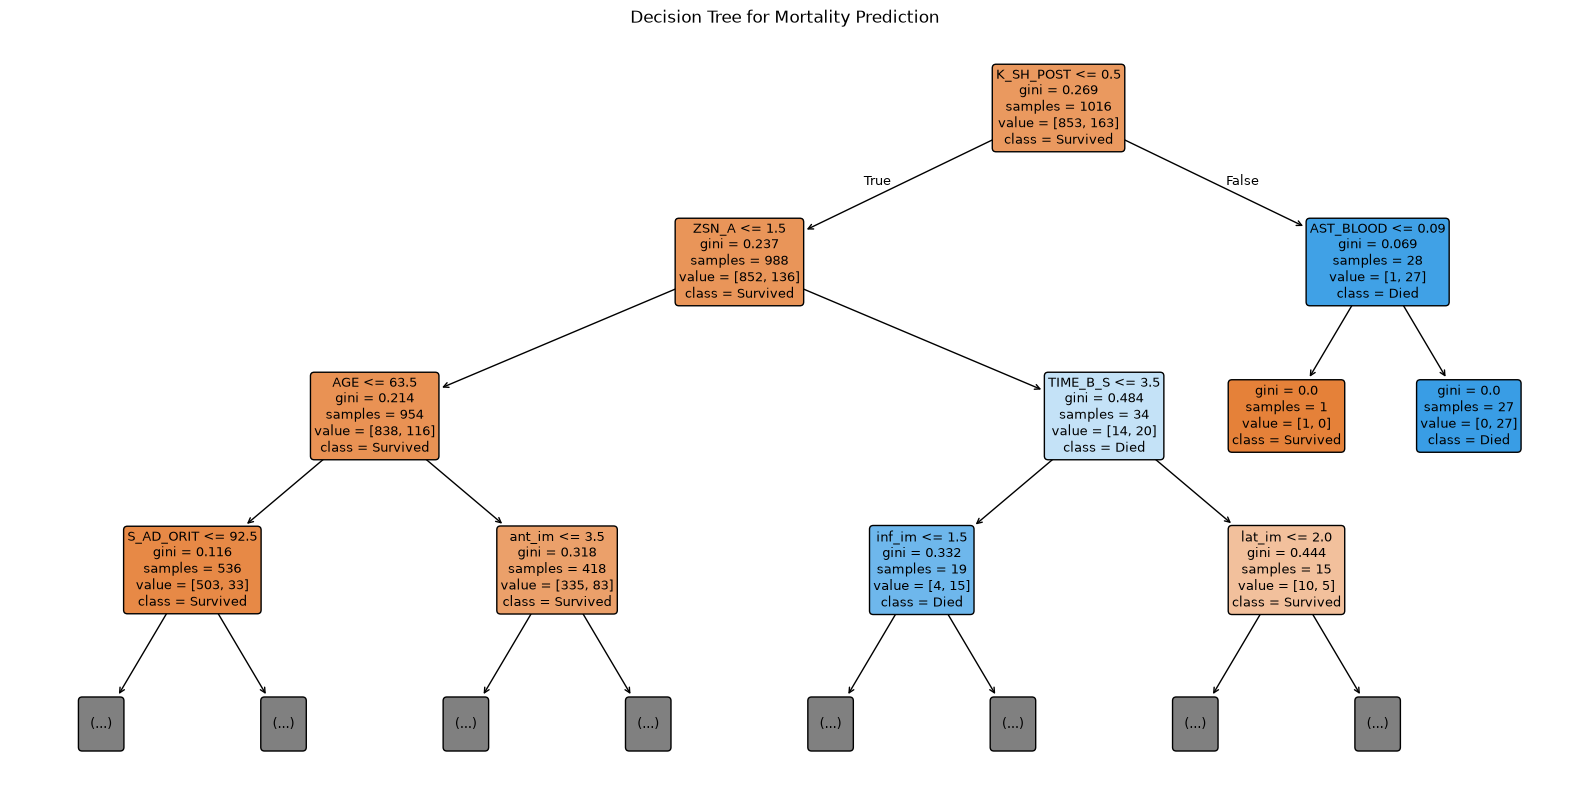

In [156]:
from sklearn.tree import plot_tree

plt.figure(figsize=(20, 10))

plot_tree(
    dt_final_unbalanced,
    feature_names=X_train.columns,
    class_names=['Survived', 'Died'],
    filled=True,
    rounded=True,
    max_depth=3,
    fontsize=9
)

plt.title('Decision Tree for Mortality Prediction')
plt.show()

## Test data

In [96]:
# Drop the same 3 columns removed from the training dataset
df_test = df_test.drop(columns=top_3_missing)

# Remove observations with missing AGE
df_test = df_test.dropna(subset=['AGE']).copy()

# Apply median imputation using training medians
df_test[numerical_cols] = median_imputer.transform(
    df_test[numerical_cols]
)

# Apply mode imputation using training modes
df_test[categorical_cols] = mode_imputer.transform(
    df_test[categorical_cols]
)

# Check remaining missing values
print("Missing values:", df_test.isnull().sum().sum())

# Check dimensions
print("Test dataset shape:", df_test.shape)

Missing values: 0
Test dataset shape: (339, 105)


In [164]:
# Test predictors and target
X_test = df_test.drop(columns=['mortality'])
y_test = df_test['mortality']

# Ensure predictors have the same order as training
X_test = X_test[X_train.columns]

# Predict mortality on unseen test data
y_test_pred  = dt_final_balanced.predict(X_test)

# Compare actual and predicted mortality
test_results = pd.DataFrame({
    'Actual': y_test,
    'Predicted': y_test_pred
})

print(test_results.head(10))

   Actual  Predicted
0       0          0
1       0          0
2       0          0
3       0          0
4       0          1
5       0          0
6       0          1
7       0          0
8       0          0
9       0          0


In [165]:
# Calculate performance metrics
test_accuracy = accuracy_score(y_test, y_test_pred_unbalanced)
test_precision = precision_score(y_test, y_test_pred_unbalanced, zero_division=0)
test_recall = recall_score(y_test, y_test_pred_unbalanced, zero_division=0)
test_f1 = f1_score(y_test, y_test_pred_unbalanced, zero_division=0)

# Display results
print("Final Decision Tree Performance")
print("-------------------------------")
print("Test Accuracy:", test_accuracy)
print("Test Precision:", test_precision)
print("Test Recall:", test_recall)
print("Test F1-score:", test_f1)

# Full classification report
print("\nClassification Report:")
print(classification_report(y_test, y_test_pred, zero_division=0))

Final Decision Tree Performance
-------------------------------
Test Accuracy: 0.855457227138643
Test Precision: 0.631578947368421
Test Recall: 0.2222222222222222
Test F1-score: 0.3287671232876712

Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.73      0.82       285
           1       0.33      0.70      0.45        54

    accuracy                           0.73       339
   macro avg       0.63      0.72      0.63       339
weighted avg       0.83      0.73      0.76       339



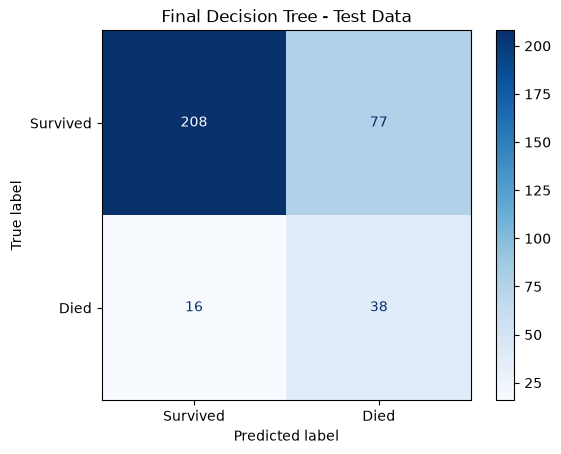

In [166]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Calculate confusion matrix
cm = confusion_matrix(y_test, y_test_pred, labels=[0, 1])

# Plot confusion matrix
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['Survived', 'Died']
)

disp.plot(cmap='Blues')

plt.title('Final Decision Tree - Test Data')
plt.show()

Decision Tree AUC Score: 0.7887


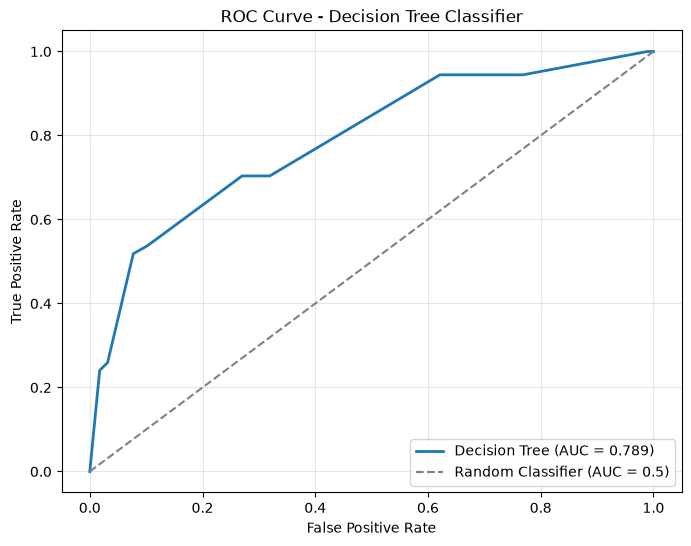

In [159]:
from sklearn.metrics import roc_curve, roc_auc_score
y_prob = dt_final_balanced.predict_proba(X_test)[:, 1]

# Calculate ROC curve
fpr, tpr, thresholds = roc_curve(y_test, y_prob)

# Calculate AUC score
auc_score = roc_auc_score(y_test, y_prob)

print(f"Decision Tree AUC Score: {auc_score:.4f}")

plt.figure(figsize=(8, 6))

# Plot ROC curve
plt.plot(
    fpr,
    tpr,
    label=f"Decision Tree (AUC = {auc_score:.3f})",
    linewidth=2
)

# Random classifier reference line
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="grey",
    label="Random Classifier (AUC = 0.5)"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Decision Tree Classifier")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)

plt.show()

## Conclusion

## References
https://archive.ics.uci.edu/dataset/579/myocardial+infarction+complications

 https://developers.google.com/machine-learning/crash-course/overfitting/imbalanced-datasets

 https://scikit-learn.org/stable/modules/generated/sklearn.tree.DecisionTreeClassifier.html
 
 https://www.datacamp.com/tutorial/decision-tree-classification-python


